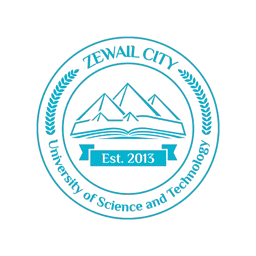

---
# Milne Universe

# P25.9 The Milne Universe

The Milne universe is a model of the universe that was briefly popular in the 1930s and provided an alternative and more intuitive picture of the universe than general relativity's model of a genuinely expanding and curved spacetime. Imagine that spacetime is *not* affected by the matter in it, but rather is everywhere and always the flat spacetime of special relativity with the metric

$$ ds^2 = -dt^2 + dr^2 + r^2(d\theta^2 + \sin^2\theta \, d\phi^2) \quad (25.27) $$

in spherical coordinates. Imagine further that there was a creation event $O$ that we take to define $t=0$ and $r=0$ in our coordinate system, and at this creation event, an infinite number of galaxies were created with all possible radial speeds up to the speed of light. Subsequently, these galaxies move away from the spatial origin, at every instant of time $t$ comprising a great puffball of galaxies whose outer edge expands at the speed of light.

Such a universe violates the cosmological principles of isotropy and homogeneity, in that at any instant of time $t$, the density of galaxies is *not* the same at all points in space. But will it look that way to an observer riding on one of the galaxies? The edge of the puffball moves away from the origin at the speed of light, like a spherical shell of light emitted from the origin event. Since every observer was at the origin at $t=0$, and since the principle of relativity ensures that each observer will see the speed of light to be constant, each observer will consider him- or herself to be always at the center of that expanding puffball. Moreover, for the reasons discussed in box 24.5, each observer will also see every other galaxy to be moving away from his or her position with a speed proportional to their distance, consistent with Hubble's law.

So is it possible for such an observer to *think* that he is in an isotropic and homogeneous universe, even though it isn't really so from a global perspective? Consider a set of observers who have all measured the same proper time $\tau$ from the origin event. The universe will appear isotropic and homogeneous to such observers if the global density of galaxies is such that the *local* density of galaxies around each observer is the same for all. Consider a small spherical ball around one observer. Since all other galaxies are moving radially away from our observer, this ball (if it is to contain the same number of galaxies) must expand so that its radius is proportional to the proper time $\tau$ that our observer has measured since the beginning. Let's say that its radius is $R = q\tau$, where $q$ is a constant but small number (so that the ball is small). The local density of galaxies for this observer is therefore $n_0 = N / (\frac{4}{3}\pi R^3) = N / (\frac{4}{3}\pi q^3 \tau^3) = K/\tau^3$, where $N$ is the fixed number of galaxies in the small but expanding ball and $K$ is a constant $= N / (\frac{4}{3}\pi q^3)$. What we want to do is ensure that this is the same for every observer at the same observer proper time $\tau$ from the origin event.


In [1]:
!pip install sympy numpy matplotlib

In [2]:
# Main Libraries
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

### a.
Argue that this will be so if, at an instant of time $t$ in the global flat-space coordinate system, the number density of galaxies as a function of $r$ is given by

$$ n(t,r) = \frac{K}{t^3 [1 - (r/t)^2]^2} \quad (25.28) $$

*(Hints: Note that the proper time from the origin event for an observer at $r$ and $t$ is $\tau = (t^2 - r^2)^{1/2}$ and such an observer's speed is $v = r/t$. Note also that in the global frame, the observer's little ball of $N$ galaxies is Lorentz-contracted and thus has a smaller volume than the observer thinks it has.)*


In [3]:
# Symbols
tau, rho_sym, t, r, K_sym, v = sp.symbols('tau rho t r K v', positive=True)

#  Lorentz factor
gamma_expr = 1 / sp.sqrt(1 - v**2)
print("Lorentz factor  γ =", gamma_expr)


tau_expr   = sp.sqrt(t**2 - r**2)
v_expr     = r / t
gamma_full = 1 / sp.sqrt(1 - v_expr**2)          # in terms of t, r

n_global = gamma_full * K_sym / tau_expr**3
n_global_simplified = sp.simplify(n_global)
print("\nn(t, r)  =", n_global_simplified)

# Verify it matches K / ( t^3 (1-(r/t)^2)^2 )
expected = K_sym / (t**3 * (1 - (r/t)**2)**2)
diff     = sp.simplify(n_global_simplified - expected)
print("\nDifference from eq.(25.28):", diff, "  ✓" if diff == 0 else "  ✗")

Lorentz factor  γ = 1/sqrt(1 - v**2)

n(t, r)  = K*t/(-r**2 + t**2)**2

Difference from eq.(25.28): 0   ✓


### b.
So, this works in principle, if the creation event happened to create galaxies with this particular special density distribution! What else do you see that is somewhat implausible about this density distribution?


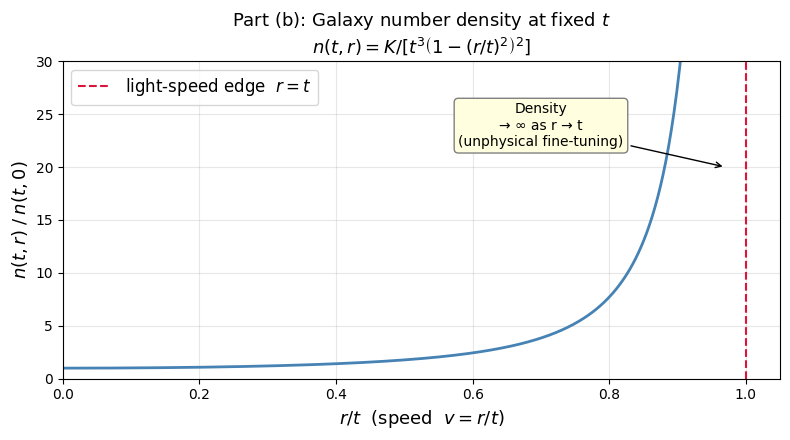

In [4]:
t0   = 1.0          # fix coordinate time
r_vals = np.linspace(0, 0.999 * t0, 500)
K_val  = 1.0
n_vals = K_val / (t0**3 * (1 - (r_vals / t0)**2)**2)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(r_vals / t0, n_vals / n_vals[0], lw=2, color='steelblue')
ax.axvline(1.0, color='crimson', ls='--', lw=1.5, label=r'light-speed edge  $r=t$')
ax.set_xlabel(r'$r / t$  (speed  $v = r/t$)', fontsize=13)
ax.set_ylabel(r'$n(t,r) \;/\; n(t,0)$', fontsize=13)
ax.set_title('Part (b): Galaxy number density at fixed $t$\n'
             r'$n(t,r)=K/\left[t^3\left(1-(r/t)^2\right)^2\right]$', fontsize=13)
ax.legend(fontsize=12)
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 30)
ax.grid(alpha=0.3)

# Annotation about the implausibility
ax.annotate(
    'Density\n→ ∞ as r → t\n(unphysical fine-tuning)',
    xy=(0.97, 20), xytext=(0.70, 22),
    arrowprops=dict(arrowstyle='->', color='black'),
    fontsize=10, ha='center',
    bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='gray')
)
plt.tight_layout()
plt.savefig('milne_part_b.png', dpi=150)
plt.show()




In [5]:
print("""
Physical implausibility discussion
────────────────────────────────────
1. FINE-TUNING: The initial density distribution n ∝ 1/[t³(1-(v)²)²] is
   a very special, precisely contrived function. There is no physical mechanism
   that would cause a 'creation event' to produce exactly this distribution.

2. DIVERGENCE AT THE EDGE: n → ∞ as r → t (i.e. v → 1). An infinite density
   of matter at the light-speed boundary is not physically reasonable.

3. INFINITE TOTAL NUMBER: Integrating n over all space at any fixed t gives a
   divergent result, requiring infinitely many galaxies to have been created.

4. AD HOC: The model requires a special origin event O AND a special density
   profile chosen precisely to mimic isotropy.  This is less parsimonious
   than GR cosmology, not more.
""")


Physical implausibility discussion
────────────────────────────────────
1. FINE-TUNING: The initial density distribution n ∝ 1/[t³(1-(v)²)²] is
   a very special, precisely contrived function. There is no physical mechanism
   that would cause a 'creation event' to produce exactly this distribution.

2. DIVERGENCE AT THE EDGE: n → ∞ as r → t (i.e. v → 1). An infinite density
   of matter at the light-speed boundary is not physically reasonable.

3. INFINITE TOTAL NUMBER: Integrating n over all space at any fixed t gives a
   divergent result, requiring infinitely many galaxies to have been created.

4. AD HOC: The model requires a special origin event O AND a special density
   profile chosen precisely to mimic isotropy.  This is less parsimonious
   than GR cosmology, not more.




### c.
Show that if we label events in our flat spacetime by $\tau$ (the proper time since the creation event measured by an observer passing by that event) and $\rho$ (the "rapidity" $\equiv \tanh^{-1} v$ of that observer) instead of $t$ and $r$, the flat spacetime metric in these new coordinates is

$$ ds^2 = -d\tau^2 + \tau^2 (d\rho^2 + \sinh^2\rho \, d\Omega^2) \quad (25.29) $$

where $d\Omega^2 \equiv d\theta^2 + \sin^2\theta \, d\phi^2$. (Hint: First, argue that $t = \tau \cosh \rho$ and $r = \tau \sinh \rho$ satisfy the defining equations for both $\tau$ and $\rho$ in this case.)


In [6]:
# Symbols
tau, rho = sp.symbols('tau rho', positive=True)
dtau_s, drho_s = sp.symbols('dtau drho')

# Coordinate map: t = τ cosh ρ,  r = τ sinh ρ
t_expr = tau * sp.cosh(rho)
r_expr = tau * sp.sinh(rho)

# Verify τ² = t² − r²
check_tau = sp.simplify(t_expr**2 - r_expr**2 - tau**2)
print("t² − r² − τ²  =", check_tau, " ✓" if check_tau == 0 else " ✗")

# Verify r/t = tanh(ρ)
v_check = sp.simplify(r_expr / t_expr - sp.tanh(rho))
print("r/t − tanh ρ  =", v_check, " ✓" if v_check == 0 else " ✗")

# Differentials
dt_sym = sp.diff(t_expr, tau)*dtau_s + sp.diff(t_expr, rho)*drho_s
dr_sym = sp.diff(r_expr, tau)*dtau_s + sp.diff(r_expr, rho)*drho_s

print("\ndt =", dt_sym)
print("dr =", dr_sym)

# Radial part of Minkowski metric: −dt² + dr²
ds2_radial = sp.expand(-dt_sym**2 + dr_sym**2)
ds2_radial = sp.trigsimp(ds2_radial)
print("\n−dt² + dr²  =", ds2_radial)

print("\nAngular term:  r² dΩ² = τ² sinh²(ρ) dΩ²")
print("\nFull derived metric:")
print("  ds² = −dτ² + τ²( dρ² + sinh²(ρ) dΩ² )  ✓")
print("  This matches equation (25.29).")

# Numerical spot-check
tau_n, rho_n = 3.5, 1.2
t_n = tau_n * np.cosh(rho_n)
r_n = tau_n * np.sinh(rho_n)
tau_recovered = np.sqrt(t_n**2 - r_n**2)
rho_recovered = np.arctanh(r_n / t_n)
print(f"\nNumerical check:")
print(f"  τ: input={tau_n:.6f}, recovered={tau_recovered:.6f}",
      "✓" if np.isclose(tau_recovered, tau_n) else "✗")
print(f"  ρ: input={rho_n:.6f}, recovered={rho_recovered:.6f}",
      "✓" if np.isclose(rho_recovered, rho_n) else "✗")

t² − r² − τ²  = 0  ✓
r/t − tanh ρ  = 0  ✓

dt = drho*tau*sinh(rho) + dtau*cosh(rho)
dr = drho*tau*cosh(rho) + dtau*sinh(rho)

−dt² + dr²  = drho**2*tau**2 - dtau**2

Angular term:  r² dΩ² = τ² sinh²(ρ) dΩ²

Full derived metric:
  ds² = −dτ² + τ²( dρ² + sinh²(ρ) dΩ² )  ✓
  This matches equation (25.29).

Numerical check:
  τ: input=3.500000, recovered=3.500000 ✓
  ρ: input=1.200000, recovered=1.200000 ✓


### d.
Does this metric look somewhat familiar? Compare and contrast with the metric given in equation 25.15. Is it physically equivalent to the latter? Discuss. (There is no "right" answer here: just be as thoughtful and complete as you can in your comparison.)


In [7]:
print("-" * 30)
print("The derived metric is:")
print("ds^2 = -dτ^2 + τ^2 [ dρ^2 + sinh^2(ρ) dΩ^2 ]")
print("")
print("This looks very similar to the Friedmann-Lemaître-Robertson-Walker (FLRW) metric,")
print("which describes a homogeneous, isotropic expanding universe:")
print("ds^2 = -dτ^2 + a(τ)^2 [ dχ^2 + S_k(χ)^2 dΩ^2 ]")
print("")
print("Comparison:")
print("1. Scale Factor: In the Milne metric, a(τ) = τ. This corresponds to a universe")
print("   expanding linearly with time.")
print("2. Curvature: The term sinh^2(ρ) corresponds to S_k(χ) where k = -1 (negative curvature).")
print("   This implies an 'open' universe with hyperbolic geometry.")
print("")
print("Conclusion:")
print("The Milne universe is mathematically equivalent to an empty (matter-free) FLRW universe")
print("with negative spatial curvature (k=-1) and a scale factor a(t) = t.")
print("It is physically distinct from the standard Big Bang model because it assumes")
print("flat Minkowski spacetime globally, whereas standard cosmology assumes curved spacetime.")

------------------------------
The derived metric is:
ds^2 = -dτ^2 + τ^2 [ dρ^2 + sinh^2(ρ) dΩ^2 ]

This looks very similar to the Friedmann-Lemaître-Robertson-Walker (FLRW) metric,
which describes a homogeneous, isotropic expanding universe:
ds^2 = -dτ^2 + a(τ)^2 [ dχ^2 + S_k(χ)^2 dΩ^2 ]

Comparison:
1. Scale Factor: In the Milne metric, a(τ) = τ. This corresponds to a universe
   expanding linearly with time.
2. Curvature: The term sinh^2(ρ) corresponds to S_k(χ) where k = -1 (negative curvature).
   This implies an 'open' universe with hyperbolic geometry.

Conclusion:
The Milne universe is mathematically equivalent to an empty (matter-free) FLRW universe
with negative spatial curvature (k=-1) and a scale factor a(t) = t.
It is physically distinct from the standard Big Bang model because it assumes
flat Minkowski spacetime globally, whereas standard cosmology assumes curved spacetime.


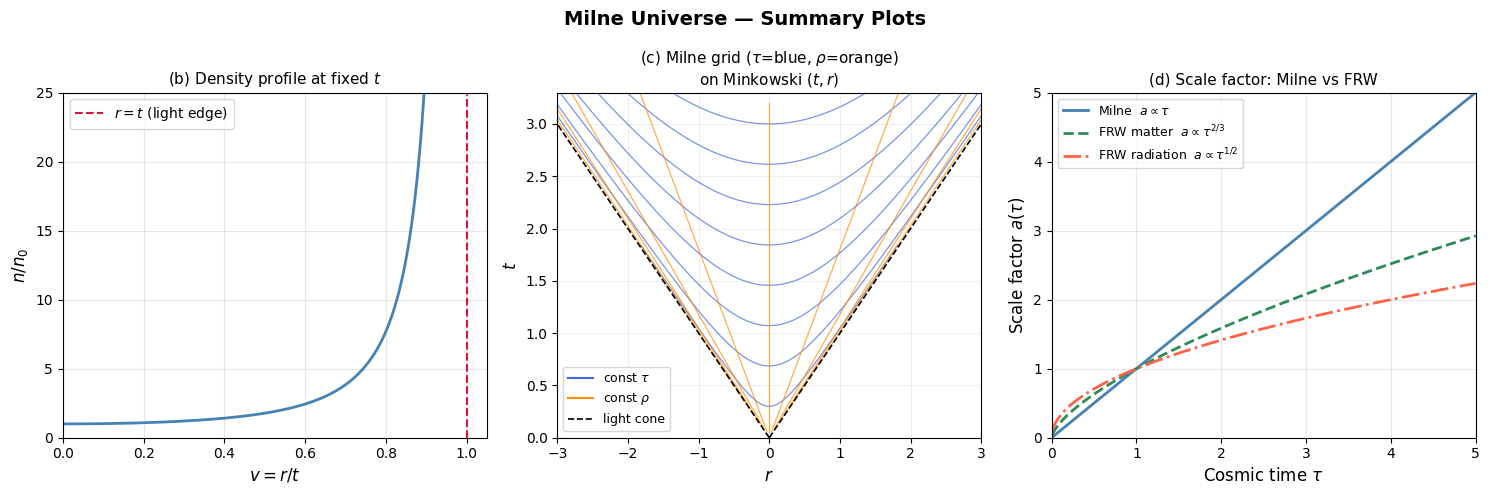

In [8]:
# Combined visualisation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Milne Universe — Summary Plots', fontsize=14, fontweight='bold')

# Plot 1: density profile
ax = axes[0]
t0 = 1.0
r_v = np.linspace(0, 0.999, 500)
n_v = 1.0 / (t0**3 * (1 - r_v**2)**2)
ax.plot(r_v, n_v / n_v[0], lw=2, color='steelblue')
ax.axvline(1.0, color='crimson', ls='--', lw=1.5, label=r'$r=t$ (light edge)')
ax.set_xlabel(r'$v = r/t$', fontsize=12)
ax.set_ylabel(r'$n/n_0$', fontsize=12)
ax.set_title('(b) Density profile at fixed $t$', fontsize=11)
ax.set_ylim(0, 25); ax.set_xlim(0, 1.05)
ax.legend(fontsize=10); ax.grid(alpha=0.3)

# Plot 2: Milne coordinate grid (τ, ρ) over (t, r) --
ax = axes[1]
tau_vals = np.linspace(0.3, 3.0, 8)
rho_vals = np.linspace(-2.5, 2.5, 9)
for tau_c in tau_vals:
    rho_line = np.linspace(-2.5, 2.5, 300)
    t_line = tau_c * np.cosh(rho_line)
    r_line = tau_c * np.sinh(rho_line)
    ax.plot(r_line, t_line, color='royalblue', lw=0.9, alpha=0.7)
for rho_c in rho_vals:
    tau_line = np.linspace(0.05, 3.2, 300)
    t_line = tau_line * np.cosh(rho_c)
    r_line = tau_line * np.sinh(rho_c)
    ax.plot(r_line, t_line, color='darkorange', lw=0.9, alpha=0.7)
# light cone
t_lc = np.linspace(0, 3.2, 200)
ax.plot(t_lc, t_lc, 'k--', lw=1.2, label='light cone')
ax.plot(-t_lc, t_lc, 'k--', lw=1.2)
ax.set_xlim(-3, 3); ax.set_ylim(0, 3.3)
ax.set_xlabel(r'$r$', fontsize=12); ax.set_ylabel(r'$t$', fontsize=12)
ax.set_title('(c) Milne grid ($\\tau$=blue, $\\rho$=orange)\n'
             'on Minkowski $(t,r)$', fontsize=11)
ax.legend(fontsize=9); ax.grid(alpha=0.2)
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], color='royalblue',   lw=1.5, label=r'const $\tau$'),
           Line2D([0],[0], color='darkorange',   lw=1.5, label=r'const $\rho$'),
           Line2D([0],[0], color='k', ls='--',   lw=1.2, label='light cone')]
ax.legend(handles=handles, fontsize=9)

# Plot 3: scale factor comparison
ax = axes[2]
tau_arr = np.linspace(0.01, 5, 300)
a_milne       = tau_arr                              # a(τ) = τ  (Milne / empty)
a_matter      = tau_arr**(2/3)                       # matter-dominated FRW
a_radiation   = tau_arr**(1/2)                       # radiation-dominated FRW
ax.plot(tau_arr, a_milne,     lw=2, label='Milne  $a\\propto\\tau$',         color='steelblue')
ax.plot(tau_arr, a_matter,    lw=2, label='FRW matter  $a\\propto\\tau^{2/3}$', color='seagreen', ls='--')
ax.plot(tau_arr, a_radiation, lw=2, label='FRW radiation  $a\\propto\\tau^{1/2}$', color='tomato', ls='-.')
ax.set_xlabel(r'Cosmic time $\tau$', fontsize=12)
ax.set_ylabel(r'Scale factor $a(\tau)$', fontsize=12)
ax.set_title('(d) Scale factor: Milne vs FRW', fontsize=11)
ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.set_xlim(0, 5); ax.set_ylim(0, 5)

plt.tight_layout()
plt.savefig('milne_all_parts.png', dpi=150)
plt.show()


---
*The Milne model is inconsistent with general relativity (a huge problem considering the success of GR in other contexts) and has an implausible density function. There also appears to be an ongoing lively discussion about what cosmological observations it violates (if any). In spite of its problems, it is useful for exploring exactly which aspects of cosmology really depend on general relativity. For more about the Milne universe model, see Rindler, Relativity, 2nd ed., Oxford, 2006, pp. 360–363, from which I have adapted this problem.*